# Optimización multiobjetivo: frentes de Pareto, NSGA-II y métricas de calidad

> Notebook 12 de la serie *metaheurísticas desde cero* · Bloque 04: tópicos avanzados.
> Anterior: [09 · Algoritmos genéticos](../03-metodos-poblacionales/09-algoritmos-geneticos.ipynb) ·
> Siguiente: [13 · Métodos híbridos y paralelos](13-metodos-hibridos-y-paralelos.ipynb)

## Contenido
1. Qué cambia cuando hay más de un objetivo (dominancia, óptimo de Pareto)
2. Métodos escalarizados: suma ponderada y $\varepsilon$-constraint
3. NSGA-II desde cero (non-dominated sorting, crowding distance, torneo con *crowded comparison*)
4. SPEA2 y MOEA/D (conceptual) y un MOEA/D simplificado
5. Indicadores de calidad: hipervolumen, spread, GD e IGD
6. Benchmarks ZDT1/ZDT2/ZDT3 con múltiples semillas
7. Problema combinatorio: mochila biobjetivo (con frente exacto para validar)
8. Resumen, ejercicios y referencias

## Qué vas a aprender / Prerrequisitos

**Aprenderás a**
- decidir si una solución es mejor que otra cuando los objetivos están en conflicto, y qué significa "resolver" un problema multiobjetivo;
- ver por qué la suma ponderada falla en frentes no convexos y cómo $\varepsilon$-constraint lo evita;
- implementar NSGA-II completo en NumPy y validarlo contra una implementación de fuerza bruta;
- medir la calidad de un conjunto de soluciones con hipervolumen, spread, GD e IGD, y comparar algoritmos con varias semillas.

**Prerrequisitos:** algoritmos genéticos (operadores de selección, cruce, mutación), nociones de NumPy y de optimización mono-objetivo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time, itertools

rng_global = np.random.default_rng(12)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
t_inicio_notebook = time.time()

## 1. Intuición: no existe "la mejor" solución

Imagina elegir un auto: queremos **minimizar el precio** y **minimizar el consumo**. Un auto barato y eficiente puede no existir; lo normal es que mejorar uno empeore el otro. Entonces ya no hay un único óptimo, sino un **conjunto de compromisos** (*trade-offs*). La tarea de un algoritmo multiobjetivo es entregar ese conjunto de la forma más completa y diversa posible, y la decisión final la toma una persona.

### Formulación
Un problema multiobjetivo (minimización) es

$$\min_{x\in\mathcal X}\; \mathbf f(x)=\big(f_1(x),\dots,f_m(x)\big).$$

**Dominancia de Pareto.** $x$ domina a $y$ ($x\prec y$) si
$$\forall i:\ f_i(x)\le f_i(y)\quad\text{y}\quad\exists j:\ f_j(x)<f_j(y).$$

- $x^{*}$ es **Pareto-óptimo** si ningún $y\in\mathcal X$ lo domina.
- El **conjunto de Pareto** $\mathcal P^{*}$ es el conjunto de todos los Pareto-óptimos; su imagen $\mathbf f(\mathcal P^{*})$ es el **frente de Pareto**.
- Dos soluciones pueden ser **incomparables** (ninguna domina a la otra): es el caso típico y lo que hace al problema interesante.

La relación $\prec$ es un **orden parcial** estricto (irreflexiva, transitiva y asimétrica); por eso podemos "pelar" un conjunto en capas (frentes) como veremos en NSGA-II.

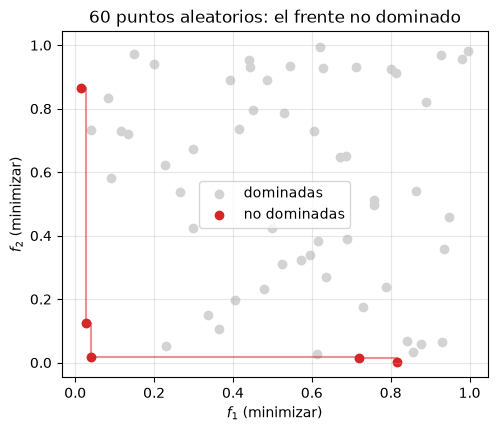

no dominadas: 5 de 60


In [2]:
def dominates(a, b):
    '''True si el vector de objetivos a domina a b (minimización).'''
    return bool(np.all(a <= b) and np.any(a < b))

def nd_bruta(F):
    '''Índices no dominados por fuerza bruta, O(N^2 m). Sirve de referencia para validar.'''
    N = len(F)
    return np.array([i for i in range(N)
                     if not any(dominates(F[j], F[i]) for j in range(N) if j != i)])

rng = np.random.default_rng(0)
F = rng.random((60, 2))
nd = nd_bruta(F)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(*F.T, c="lightgray", label="dominadas")
o = nd[np.argsort(F[nd, 0])]
ax.step(F[o, 0], F[o, 1], where="post", c="C3", alpha=.5)
ax.scatter(*F[nd].T, c="C3", label="no dominadas")
ax.set_xlabel("$f_1$ (minimizar)"); ax.set_ylabel("$f_2$ (minimizar)")
ax.set_title("60 puntos aleatorios: el frente no dominado"); ax.legend(); plt.show()
print("no dominadas:", len(nd), "de", len(F))

Observa la región que una solución del frente domina: todo el cuadrante "arriba a la derecha". Eso motiva el **hipervolumen** (sección 5): el área dominada por el conjunto.

Antes de ir a las metaheurísticas, veamos el enfoque clásico: convertir el problema en uno mono-objetivo.

## 2. Métodos escalarizados

### 2.1 Suma ponderada
$$\min_x \; \sum_{i=1}^m w_i f_i(x),\qquad w_i\ge 0,\ \sum_i w_i=1.$$
Cada vector de pesos produce (a lo sumo) una solución del frente. **Límite fundamental:** la suma ponderada solo alcanza los puntos del frente que están en el *casco convexo* (soluciones "soportadas"). Geométricamente, la curva de nivel $w_1f_1+w_2f_2=c$ es una recta que se desliza hacia el origen hasta tocar la región factible; si el frente es cóncavo (visto desde el origen), la recta toca primero los extremos y nunca los puntos interiores.

### 2.2 $\varepsilon$-constraint
$$\min_x f_1(x)\quad\text{s.a.}\quad f_j(x)\le\varepsilon_j\ (j\ge 2),\ x\in\mathcal X.$$
Variando $\varepsilon$ se recorre **todo** el frente (incluso zonas no convexas), a costa de resolver más subproblemas y de que algunos sean infactibles si $\varepsilon$ está mal elegido.

Para ilustrarlo usamos una versión de **2 variables** de los problemas ZDT (más abajo los definimos completos): $f_1=x_1$, $g=1+9x_2$, $f_2=g\,h(f_1/g)$ con $h(u)=1-\sqrt u$ (frente convexo) o $h(u)=1-u^2$ (frente cóncavo). Muestreamos 200 000 puntos factibles y resolvemos los subproblemas escalarizados sobre esa nube.

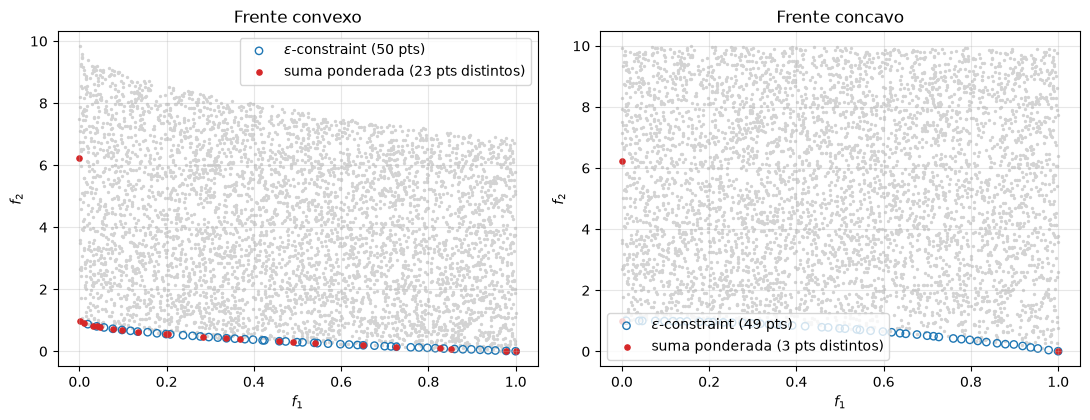

frente convexo : 101 pesos ->  23 soluciones distintas | 51 valores de eps ->  50 soluciones distintas
frente concavo : 101 pesos ->   3 soluciones distintas | 51 valores de eps ->  49 soluciones distintas


In [3]:
def zdt_2var(x1, x2, tipo):
    g = 1 + 9 * x2
    u = x1 / g
    h = 1 - np.sqrt(u) if tipo == "convexo" else 1 - u**2
    return np.column_stack([x1, g * h])

rng = np.random.default_rng(1)
X = rng.random((200_000, 2))
nubes = {t: zdt_2var(X[:, 0], X[:, 1], t) for t in ("convexo", "concavo")}

def suma_ponderada(F, w):
    return int(np.argmin(F @ np.array([w, 1 - w])))

def eps_constraint(F, eps):
    '''min f2 sujeto a f1 <= eps (se minimiza f2 y se acota f1).'''
    ok = F[:, 0] <= eps
    if not ok.any(): return None
    idx = np.where(ok)[0]
    return int(idx[np.argmin(F[idx, 1])])

pesos = np.linspace(0, 1, 101)
epsilons = np.linspace(0.0, 1.0, 51)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.3))
res_escal = {}
for ax, (t, F) in zip(axs, nubes.items()):
    idx_ws = {suma_ponderada(F, w) for w in pesos}
    idx_ec = {i for i in (eps_constraint(F, e) for e in epsilons) if i is not None}
    res_escal[t] = (len(idx_ws), len(idx_ec))
    ax.scatter(*F[::40].T, s=2, c="lightgray")
    ax.scatter(*F[list(idx_ec)].T, s=28, facecolors="none", edgecolors="C0", label=f"$\\varepsilon$-constraint ({len(idx_ec)} pts)")
    ax.scatter(*F[list(idx_ws)].T, s=14, c="C3", label=f"suma ponderada ({len(idx_ws)} pts distintos)")
    ax.set_title(f"Frente {t}"); ax.set_xlabel("$f_1$"); ax.set_ylabel("$f_2$"); ax.legend()
plt.tight_layout(); plt.show()
for t, (a, b) in res_escal.items():
    print(f"frente {t:8s}: 101 pesos -> {a:3d} soluciones distintas | 51 valores de eps -> {b:3d} soluciones distintas")

**Lectura.** En el frente convexo los 101 pesos producen decenas de soluciones distintas a lo largo de la curva (no uniformemente espaciadas: pesos uniformes no implican puntos uniformes); en el cóncavo, los 101 pesos colapsan a muy pocas soluciones (los extremos y, a lo sumo, algún punto aislado), mientras $\varepsilon$-constraint sigue barriendo casi todo el frente. Los conteos impresos arriba lo confirman. Además, la suma ponderada exige un solver por cada vector de pesos.

Las metaheurísticas poblacionales atacan ambos problemas a la vez: mantienen un conjunto de soluciones que aproxima **todo el frente en una sola corrida**, sin supuestos de convexidad.

## 3. NSGA-II desde cero

NSGA-II (Deb, Pratap, Agarwal y Meyarivan, 2002) es el MOEA (*multi-objective evolutionary algorithm*) más usado. Sus tres ingredientes:

1. **Non-dominated sorting rápido:** divide la población en frentes $\mathcal F_1,\mathcal F_2,\dots$; $\mathcal F_1$ no está dominado por nadie, $\mathcal F_2$ solo por $\mathcal F_1$, etc. Se define el *rango* de cada individuo. Complejidad $O(mN^2)$ (el método ingenuo es $O(mN^3)$).
2. **Crowding distance:** estimador de densidad. Dentro de un frente, para cada objetivo se ordena y cada individuo recibe $\frac{f_k^{(i+1)}-f_k^{(i-1)}}{f_k^{\max}-f_k^{\min}}$; los extremos reciben $\infty$. La distancia total es la suma sobre objetivos: perímetro (semi) del cuboide formado por los vecinos.
3. **Operador de comparación apiñada** (*crowded comparison*): $i\prec_n j$ si $\text{rango}_i<\text{rango}_j$, o si son del mismo rango y $d_i>d_j$. Se usa en el torneo binario y en la selección de supervivientes (elitismo: se mezcla padres + hijos, $2N$, y se queda con los $N$ mejores según $\prec_n$).

```
NSGA-II(N, G):
    P ← población aleatoria de tamaño N;  evaluar
    repetir G veces:
        asignar rango (non-dominated sort) y crowding a P
        Q ← N hijos: torneo binario con ≺n → cruce (SBX) → mutación (polinomial)
        R ← P ∪ Q                      # 2N individuos
        frentes ← non-dominated-sort(R)
        P' ← ∅
        para cada frente F_k en orden:
            si |P'| + |F_k| ≤ N:  P' ← P' ∪ F_k
            si no:  ordenar F_k por crowding descendente; completar P' hasta N; salir
        P ← P'
    devolver el primer frente de P
```
Implementamos primero las dos piezas centrales y las **validamos** contra fuerza bruta.

In [4]:
def dom_matrix(F):
    '''D[i, j] = True si i domina a j (vectorizado).'''
    le = (F[:, None, :] <= F[None, :, :]).all(2)
    lt = (F[:, None, :] <  F[None, :, :]).any(2)
    return le & lt

def fast_nds(F):
    '''Non-dominated sorting rápido. Devuelve (rango por individuo, lista de frentes).'''
    N = len(F)
    D = dom_matrix(F)
    n_dom = D.sum(0).astype(int)          # cuántos dominan a cada individuo
    rango = np.full(N, -1)
    frentes, actual, r = [], np.where(n_dom == 0)[0], 0
    while len(actual):
        rango[actual] = r
        frentes.append(actual)
        sig = []
        for p in actual:                   # quitar el frente actual del grafo
            for q in np.where(D[p])[0]:
                n_dom[q] -= 1
                if n_dom[q] == 0: sig.append(q)
        actual, r = np.array(sig, dtype=int), r + 1
    return rango, frentes

def crowding(F):
    '''Crowding distance de un conjunto (se llama sobre cada frente por separado).'''
    n, m = F.shape
    d = np.zeros(n)
    if n <= 2:
        d[:] = np.inf; return d
    for k in range(m):
        o = np.argsort(F[:, k], kind="stable")
        d[o[0]] = d[o[-1]] = np.inf
        rg = F[o[-1], k] - F[o[0], k]
        if rg > 0:
            d[o[1:-1]] += (F[o[2:], k] - F[o[:-2], k]) / rg
    return d

# --- Validación 1: el primer frente coincide con la fuerza bruta; los rangos son consistentes
rng = np.random.default_rng(3)
for trial in range(20):
    m = rng.integers(2, 5)
    F = rng.integers(0, 12, size=(80, m)).astype(float)   # enteros -> muchos empates
    rango, frentes = fast_nds(F)
    assert set(frentes[0]) == set(nd_bruta(F)), "frente 1 distinto de fuerza bruta"
    # propiedad: nadie en el frente k domina a alguien en un frente anterior, y todo individuo
    # de rango k>0 es dominado por alguien de rango k-1
    for k, fr in enumerate(frentes):
        for i in fr:
            if k > 0: assert any(dominates(F[j], F[i]) for j in frentes[k-1])
            assert not any(dominates(F[i], F[j]) for j in np.where(rango < k)[0])
print("non-dominated sort: validado en 20 instancias aleatorias (m=2..4, con empates)")

# --- Validación 2: crowding en un caso a mano. Puntos (0,3),(1,2),(2,1.5),(3,0)
Fc = np.array([[0, 3], [1, 2], [2, 1.5], [3, 0]], float)
print("crowding:", crowding(Fc))
# punto 1: (2-0)/3 + (3-1.5)/3 = 0.6667+0.5 ; punto 2: (3-1)/3 + (2-0)/3 = 0.6667+0.6667
assert np.allclose(crowding(Fc)[1:3], [2/3 + 0.5, 2/3 + 2/3])
print("crowding: coincide con el cálculo manual")

non-dominated sort: validado en 20 instancias aleatorias (m=2..4, con empates)
crowding: [       inf 1.16666667 1.33333333        inf]
crowding: coincide con el cálculo manual


### Operadores de variación para variables reales
- **SBX** (*simulated binary crossover*, índice de distribución $\eta_c$): genera hijos simétricos respecto a los padres con $\beta$ dependiente de un uniforme $u$:
  $\beta=(2u)^{1/(\eta_c+1)}$ si $u\le 0.5$, y $\beta=\big(1/(2(1-u))\big)^{1/(\eta_c+1)}$ si no; $c_{1,2}=\tfrac12[(1\pm\beta)p_1+(1\mp\beta)p_2]$. Un $\eta_c$ grande produce hijos cercanos a los padres.
- **Mutación polinomial** (índice $\eta_m$, probabilidad $1/n$ por variable).

Escribimos el algoritmo de forma **genérica**: recibe funciones `evaluar`, `inicializar` y `variacion`, de modo que el mismo núcleo sirve para variables reales (ZDT) y binarias (mochila).

In [5]:
def sbx(P1, P2, rng, eta=15.0, pc=0.9, lo=0.0, hi=1.0):
    '''SBX vectorizado sobre matrices (N, n). Devuelve dos matrices de hijos.'''
    u = rng.random(P1.shape)
    beta = np.where(u <= 0.5, (2 * u) ** (1 / (eta + 1)), (1 / (2 * (1 - u))) ** (1 / (eta + 1)))
    c1 = 0.5 * ((1 + beta) * P1 + (1 - beta) * P2)
    c2 = 0.5 * ((1 - beta) * P1 + (1 + beta) * P2)
    hacer = rng.random((P1.shape[0], 1)) < pc          # cruzar solo con prob. pc
    c1 = np.where(hacer, c1, P1); c2 = np.where(hacer, c2, P2)
    return np.clip(c1, lo, hi), np.clip(c2, lo, hi)

def mut_polinomial(X, rng, eta=20.0, lo=0.0, hi=1.0):
    '''Mutación polinomial: cada variable con prob. 1/n.'''
    N, n = X.shape
    u = rng.random(X.shape)
    delta = np.where(u < 0.5, (2 * u) ** (1 / (eta + 1)) - 1, 1 - (2 * (1 - u)) ** (1 / (eta + 1)))
    mask = rng.random(X.shape) < 1.0 / n
    return np.clip(X + mask * delta * (hi - lo), lo, hi)

def torneo_apinado(rango, cd, n_sel, rng):
    '''Torneo binario con crowded comparison: menor rango; en empate, mayor crowding.'''
    N = len(rango)
    a = rng.integers(0, N, n_sel); b = rng.integers(0, N, n_sel)
    gana_a = (rango[a] < rango[b]) | ((rango[a] == rango[b]) & (cd[a] >= cd[b]))
    return np.where(gana_a, a, b)

def crowding_poblacion(F, frentes):
    cd = np.zeros(len(F))
    for fr in frentes: cd[fr] = crowding(F[fr])
    return cd

def seleccion_supervivientes(F, N):
    '''Elitismo de NSGA-II: llena N plazas frente a frente; el último se corta por crowding.'''
    rango, frentes = fast_nds(F)
    elegidos = []
    for fr in frentes:
        if len(elegidos) + len(fr) <= N:
            elegidos.extend(fr)
        else:
            cd = crowding(F[fr])
            orden = np.argsort(-cd, kind="stable")
            elegidos.extend(fr[orden[:N - len(elegidos)]]); break
        if len(elegidos) == N: break
    return np.array(elegidos)

def nsga2(evaluar, inicializar, variacion, N, G, rng, hist_fn=None):
    '''NSGA-II genérico. evaluar(X)->F (N,m); inicializar(N,rng)->X; variacion(Xpadres,rng)->Xhijos.
    hist_fn(F_primer_frente) -> float se guarda por generación (p. ej. hipervolumen).'''
    X = inicializar(N, rng); F = evaluar(X)
    hist = []
    for g in range(G):
        rango, frentes = fast_nds(F)
        cd = crowding_poblacion(F, frentes)
        pad = torneo_apinado(rango, cd, N, rng)
        Xh = variacion(X[pad], rng); Fh = evaluar(Xh)
        XR = np.vstack([X, Xh]); FR = np.vstack([F, Fh])
        idx = seleccion_supervivientes(FR, N)
        X, F = XR[idx], FR[idx]
        if hist_fn is not None:
            hist.append(hist_fn(F[fast_nds(F)[1][0]]))
    f1 = fast_nds(F)[1][0]
    return X, F, f1, hist

## 4. SPEA2 y MOEA/D (conceptual) y un MOEA/D simplificado

NSGA-II no es la única familia. Tres filosofías para "presionar" hacia el frente y a la vez mantener diversidad:

| Algoritmo | Presión de selección | Diversidad | Archivo / elitismo |
|---|---|---|---|
| **NSGA-II** | rango de no-dominancia | crowding distance (por objetivo) | $N$ mejores de padres+hijos |
| **SPEA2** (Zitzler et al., 2001) | *fitness* de fuerza (strength) | distancia al $k$-ésimo vecino | archivo externo de tamaño fijo |
| **MOEA/D** (Zhang y Li, 2007) | descomposición en subproblemas escalares | vecindarios de pesos | una solución por subproblema |

**SPEA2.** A cada individuo $i$ se le asigna una *fuerza* $S(i)=|\{j: i\prec j\}|$ y un valor crudo $R(i)=\sum_{j\prec i}S(j)$ (cuántos individuos dominan a quienes lo dominan; $R=0$ para no dominados). Se suma una densidad $D(i)=1/(\sigma_i^k+2)$ con $\sigma_i^k$ la distancia al $k$-ésimo vecino ($k\approx\sqrt{N}$): $F(i)=R(i)+D(i)$. El archivo se trunca iterativamente eliminando al individuo más cercano a otro (preserva los extremos).

**MOEA/D.** Se escoge un conjunto de vectores de pesos $\lambda^1,\dots,\lambda^N$ y se resuelven $N$ subproblemas escalares **cooperando entre vecinos** (los $T$ pesos más cercanos). La escalarización preferida es **Tchebycheff**:
$$g^{te}(x\mid\lambda,z^{*})=\max_{i}\ \lambda_i\,|f_i(x)-z_i^{*}|,$$
con $z^{*}$ el punto ideal (mínimo observado por objetivo). A diferencia de la suma ponderada, Tchebycheff **sí alcanza puntos no convexos**: todo punto Pareto-óptimo es el óptimo de algún $\lambda$. Un hijo creado entre vecinos reemplaza a los vecinos a los que mejora (hasta $n_r$ reemplazos).

Implementamos una versión **simplificada** de MOEA/D (2 objetivos, pesos uniformes, SBX + mutación polinomial, Tchebycheff, actualización de vecinos).

In [6]:
def moead(evaluar, inicializar, mut, cruce, N, G, rng, T=20, nr=2, hist_fn=None):
    '''MOEA/D simplificado para m=2 con descomposición de Tchebycheff.
    Devuelve (X, F) con una solución por subproblema.'''
    w1 = np.linspace(0, 1, N)
    W = np.column_stack([w1, 1 - w1])
    W = np.maximum(W, 1e-6)                                    # evita pesos exactamente 0
    dist = np.linalg.norm(W[:, None] - W[None], axis=2)
    vec = np.argsort(dist, axis=1)[:, :T]                      # T vecinos de cada subproblema
    X = inicializar(N, rng); F = evaluar(X)
    z = F.min(0)                                               # punto ideal estimado
    hist = []
    for g in range(G):
        for i in rng.permutation(N):
            a, b = rng.choice(vec[i], 2, replace=False)
            h, _ = cruce(X[a:a+1], X[b:b+1], rng)
            h = mut(h, rng)
            fh = evaluar(h)[0]
            z = np.minimum(z, fh)
            nb = vec[i]
            g_old = np.max(W[nb] * np.abs(F[nb] - z), axis=1)
            g_new = np.max(W[nb] * np.abs(fh - z), axis=1)
            mejora = nb[g_new <= g_old][:nr]                   # a lo sumo nr reemplazos
            X[mejora] = h[0]; F[mejora] = fh
        if hist_fn is not None:
            hist.append(hist_fn(F[fast_nds(F)[1][0]]))
    return X, F, fast_nds(F)[1][0], hist

## 5. Indicadores de calidad

Comparar dos conjuntos de puntos no es trivial: hay que medir tres cosas a la vez, **convergencia** (qué tan cerca del frente real), **diversidad** (qué tan bien repartido) y **cobertura** (que no falten tramos ni extremos).

| Indicador | Mide | Necesita frente real | Mejor |
|---|---|---|---|
| Hipervolumen (HV) | convergencia + diversidad (compatible con Pareto) | no (necesita punto de referencia) | mayor |
| GD (*generational distance*) | convergencia | sí | menor |
| IGD (*inverted GD*) | convergencia + cobertura | sí | menor |
| Spread ($\Delta$) | uniformidad y extensión | sí (extremos) | menor |

- **HV** (minimización, punto de referencia $r$): $\text{HV}(A)=\Lambda\big(\bigcup_{a\in A}[a,r]\big)$ (medida de Lebesgue). En 2D: ordenando por $f_1$ creciente, $\text{HV}=\sum_i (r_1-f_{1,i})(f_{2,i-1}-f_{2,i})$ con $f_{2,0}=r_2$.
- **GD** $=\sqrt{\tfrac1{|A|}\sum_{a\in A}\min_{p\in P^{*}}\|a-p\|^2}$ y **IGD** $=\sqrt{\tfrac1{|P^{*}|}\sum_{p\in P^{*}}\min_{a\in A}\|a-p\|^2}$ (aquí con raíz cuadrática; hay variantes con media simple). GD no penaliza que $A$ sea un solo punto buenísimo; IGD sí.
- **Spread** (Deb): $\Delta=\dfrac{d_f+d_l+\sum_{i=1}^{N-1}|d_i-\bar d|}{d_f+d_l+(N-1)\bar d}$, con $d_i$ distancias entre puntos consecutivos y $d_f,d_l$ distancias a los extremos del frente real. Vale 0 si la distribución es perfectamente uniforme y cubre los extremos.

In [7]:
def nd2d(F):
    '''Filtra no dominados para m=2 (minimización) en O(N log N). Devuelve los puntos ordenados por f1.'''
    o = np.lexsort((F[:, 1], F[:, 0]))
    S = F[o]
    mejor = np.minimum.accumulate(S[:, 1])
    keep = np.ones(len(S), bool)
    keep[1:] = S[1:, 1] < mejor[:-1]
    return S[keep]

def hipervolumen_2d(F, ref):
    '''Hipervolumen 2D exacto (minimización). Descarta puntos que no dominan al punto de referencia.'''
    F = F[(F[:, 0] < ref[0]) & (F[:, 1] < ref[1])]
    if len(F) == 0: return 0.0
    S = nd2d(F)
    hv, prev = 0.0, ref[1]
    for f1, f2 in S:
        hv += (ref[0] - f1) * (prev - f2)
        prev = f2
    return hv

def GD(A, P):
    d = np.min(np.linalg.norm(A[:, None] - P[None], axis=2), axis=1)
    return np.sqrt(np.mean(d**2))

def IGD(A, P):
    return GD(P, A)

def spread(A, P):
    '''Spread de Deb para 2 objetivos. P = frente real (para los extremos).'''
    S = nd2d(A)
    Pe = P[np.argsort(P[:, 0])]
    df = np.linalg.norm(S[0] - Pe[0]); dl = np.linalg.norm(S[-1] - Pe[-1])
    d = np.linalg.norm(np.diff(S, axis=0), axis=1)
    if len(d) == 0: return 1.0
    dm = d.mean()
    return (df + dl + np.abs(d - dm).sum()) / (df + dl + len(d) * dm)

# --- Validación del hipervolumen: casos a mano y Monte Carlo
ref = np.array([4.0, 4.0])
assert np.isclose(hipervolumen_2d(np.array([[1., 3.], [2., 2.], [3., 1.]]), ref), 3*1 + 2*1 + 1*1)  # =6
assert np.isclose(hipervolumen_2d(np.array([[1., 1.]]), ref), 9.0)
assert np.isclose(hipervolumen_2d(np.array([[1., 1.], [2., 2.]]), ref), 9.0)    # punto dominado no suma
rng = np.random.default_rng(5)
Fr = rng.random((15, 2)) * 3
U = rng.random((400_000, 2)) * 4
cubierto = np.zeros(len(U), bool)
for f in Fr: cubierto |= (U >= f).all(1)
hv_mc = cubierto.mean() * 16
print(f"HV exacto = {hipervolumen_2d(Fr, ref):.4f} | Monte Carlo (400k) = {hv_mc:.4f}")
assert abs(hipervolumen_2d(Fr, ref) - hv_mc) < 0.05
# GD/IGD/spread del propio frente real: 0 / 0
P = np.column_stack([np.linspace(0, 1, 50), 1 - np.sqrt(np.linspace(0, 1, 50))])
print(f"GD(P,P)={GD(P,P):.1e}  IGD(P,P)={IGD(P,P):.1e}  spread(P,P)={spread(P,P):.3f}")

HV exacto = 13.8793 | Monte Carlo (400k) = 13.8926
GD(P,P)=0.0e+00  IGD(P,P)=0.0e+00  spread(P,P)=0.277


La sensibilidad de IGD y GD a la cobertura se ve con un ejemplo: un conjunto de **un solo punto en la mitad del frente** tiene GD≈0 (está sobre el frente) pero un IGD grande.

In [8]:
A1 = P[[25]]                       # un solo punto exacto del frente
A2 = P[::5] + 0.03                 # 10 puntos repartidos, algo desplazados
print(f"un punto sobre el frente   -> GD={GD(A1,P):.4f}  IGD={IGD(A1,P):.4f}")
print(f"10 puntos repartidos (+.03)-> GD={GD(A2,P):.4f}  IGD={IGD(A2,P):.4f}")

un punto sobre el frente   -> GD=0.0000  IGD=0.3876
10 puntos repartidos (+.03)-> GD=0.0423  IGD=0.0642


## 6. Benchmarks ZDT

La familia ZDT (Zitzler, Deb y Thiele, 2000) tiene 2 objetivos y $n=30$ variables en $[0,1]$:
$$f_1(x)=x_1,\quad g(x)=1+\tfrac{9}{n-1}\sum_{i=2}^n x_i,\quad f_2(x)=g(x)\,h\!\Big(\tfrac{f_1}{g}\Big).$$

| Problema | $h(u)$ | Frente real ($g=1$) |
|---|---|---|
| ZDT1 | $1-\sqrt u$ | convexo |
| ZDT2 | $1-u^2$ | cóncavo (no convexo) |
| ZDT3 | $1-\sqrt u-u\sin(10\pi u)$ | desconectado (5 tramos) |

Los frentes reales los calculamos numéricamente: muestreamos $f_1$ densamente con $g=1$ y filtramos los no dominados (en ZDT3 esto elimina los tramos dominados por otros).

HV del frente real (ref 1.1,1.1): {'ZDT1': np.float64(0.8765), 'ZDT2': np.float64(0.5432), 'ZDT3': np.float64(1.3315)}


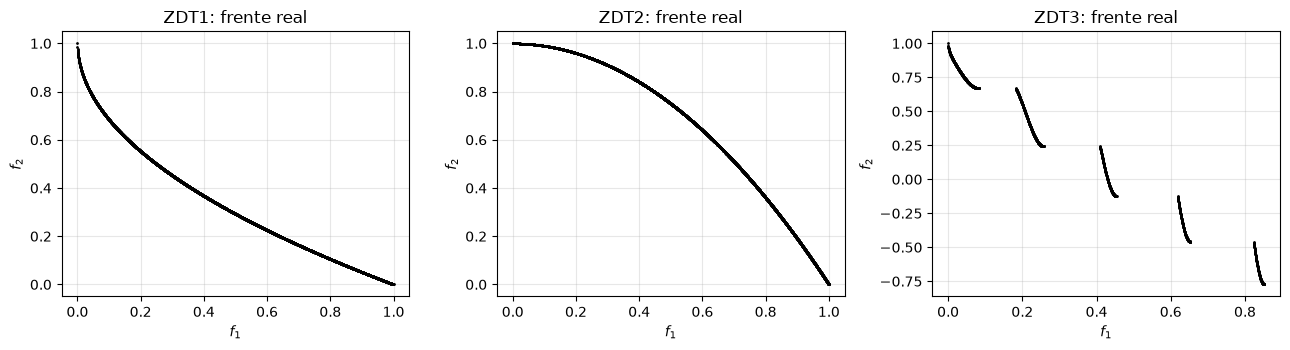

In [9]:
def zdt(tipo):
    def f(X):
        f1 = X[:, 0]
        g = 1 + 9 * X[:, 1:].mean(1)
        u = f1 / g
        h = {"ZDT1": 1 - np.sqrt(u), "ZDT2": 1 - u**2,
             "ZDT3": 1 - np.sqrt(u) - u * np.sin(10 * np.pi * u)}[tipo]
        return np.column_stack([f1, g * h])
    return f

def frente_real(tipo, n=4000):
    x = np.linspace(0, 1, n)
    X = np.column_stack([x, np.zeros((n, 29))])        # g = 1
    return nd2d(zdt(tipo)(X))

NV = 30
REF = np.array([1.1, 1.1])
reales = {t: frente_real(t) for t in ("ZDT1", "ZDT2", "ZDT3")}
hv_real = {t: hipervolumen_2d(P, REF) for t, P in reales.items()}
# validación: en g=1 el ZDT1 tiene f2 = 1 - sqrt(f1)
P1 = reales["ZDT1"]; assert np.allclose(P1[:, 1], 1 - np.sqrt(P1[:, 0]))
print("HV del frente real (ref 1.1,1.1):", {t: round(v, 4) for t, v in hv_real.items()})

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (t, P) in zip(axs, reales.items()):
    ax.plot(*P.T, ".", ms=2, c="k"); ax.set_title(f"{t}: frente real"); ax.set_xlabel("$f_1$"); ax.set_ylabel("$f_2$")
plt.tight_layout(); plt.show()

### Ejecución de NSGA-II en ZDT1/2/3
Población $N=100$, $G=400$ generaciones, SBX ($\eta_c=15$, $p_c=0.9$), mutación polinomial ($\eta_m=20$). Primero una sola semilla para ver el frente y la convergencia del hipervolumen por generación; después, varias semillas.

ZDT1: HV final / HV real = 0.9834  |  |frente 1| = 100


ZDT2: HV final / HV real = 0.9821  |  |frente 1| = 100


ZDT3: HV final / HV real = 0.9452  |  |frente 1| = 100


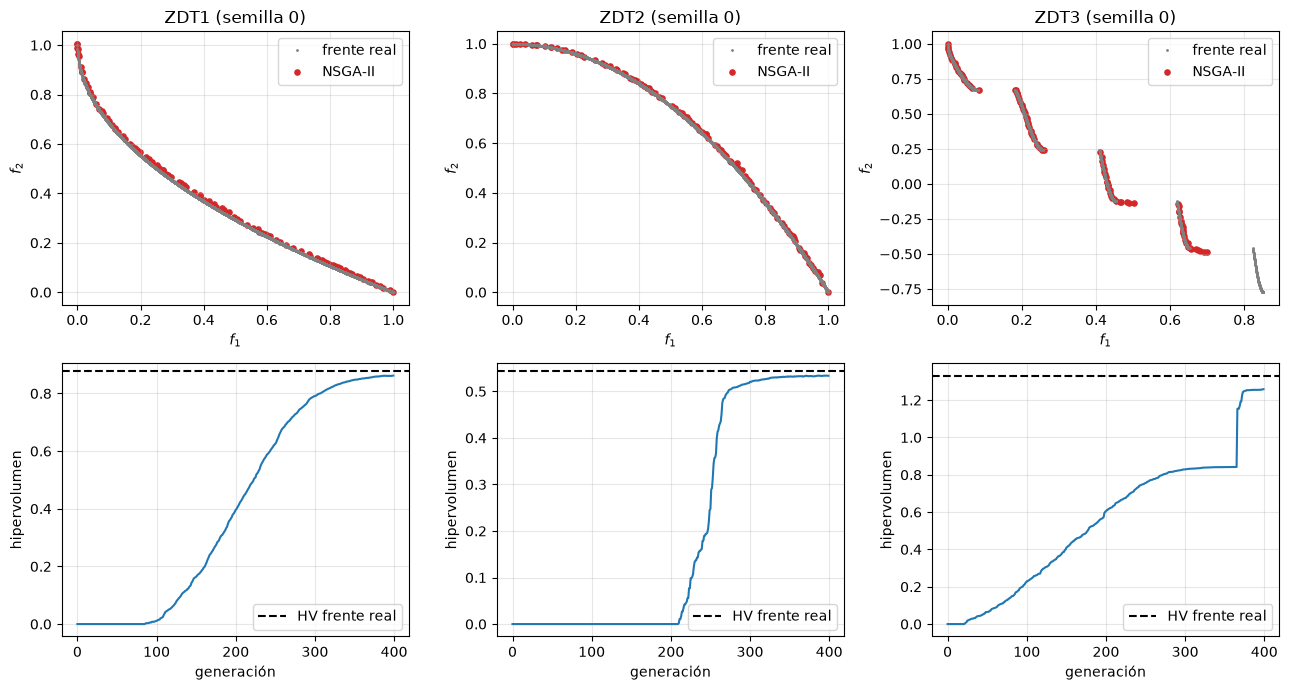

tiempo: 4.8s


In [10]:
def variacion_real(Xp, rng):
    # los padres vienen ya seleccionados: se emparejan consecutivamente
    n = len(Xp)
    perm = rng.permutation(n)
    P1, P2 = Xp[perm[: n // 2]], Xp[perm[n // 2: 2 * (n // 2)]]
    c1, c2 = sbx(P1, P2, rng)
    H = np.vstack([c1, c2])
    if len(H) < n: H = np.vstack([H, Xp[perm[-1:]]])
    return mut_polinomial(H, rng)

init_real = lambda N, rng: rng.random((N, NV))

def correr_nsga2_zdt(tipo, semilla, N=100, G=400, con_hist=False):
    rng = np.random.default_rng(semilla)
    hf = (lambda Ff: hipervolumen_2d(Ff, REF)) if con_hist else None
    return nsga2(zdt(tipo), init_real, variacion_real, N, G, rng, hist_fn=hf)

t0 = time.time()
fig, axs = plt.subplots(2, 3, figsize=(13, 7))
for j, t in enumerate(("ZDT1", "ZDT2", "ZDT3")):
    X, F, f1, hist = correr_nsga2_zdt(t, 0, con_hist=True)
    P = reales[t]
    axs[0, j].plot(*P.T, ".", ms=2, c="gray", label="frente real")
    axs[0, j].scatter(*F[f1].T, s=14, c="C3", label="NSGA-II")
    axs[0, j].set_title(f"{t} (semilla 0)"); axs[0, j].set_xlabel("$f_1$"); axs[0, j].set_ylabel("$f_2$"); axs[0, j].legend()
    axs[1, j].plot(hist, c="C0"); axs[1, j].axhline(hv_real[t], c="k", ls="--", label="HV frente real")
    axs[1, j].set_xlabel("generación"); axs[1, j].set_ylabel("hipervolumen"); axs[1, j].legend()
    print(f"{t}: HV final / HV real = {hist[-1]/hv_real[t]:.4f}  |  |frente 1| = {len(f1)}")
plt.tight_layout(); plt.show()
print(f"tiempo: {time.time()-t0:.1f}s")

**Nota de correctitud.** Al devolver el primer frente de la población final, todos los puntos son mutuamente no dominados por construcción; lo verificamos explícitamente y comprobamos que las variables se mantienen en $[0,1]$.

In [11]:
for t in ("ZDT1", "ZDT2", "ZDT3"):
    X, F, f1, _ = correr_nsga2_zdt(t, 1)
    assert X.min() >= 0 and X.max() <= 1
    assert np.allclose(F, zdt(t)(X))                       # los F guardados corresponden a los X
    assert len(nd_bruta(F[f1])) == len(f1)                  # el primer frente es mutuamente no dominado
print("NSGA-II: variables en [0,1], F consistente con X y frente 1 no dominado (ZDT1-3)")

NSGA-II: variables en [0,1], F consistente con X y frente 1 no dominado (ZDT1-3)


### Múltiples semillas y comparación con MOEA/D simplificado y búsqueda aleatoria
Una sola corrida no demuestra nada: repetimos con **6 semillas** y mismo presupuesto de evaluaciones ($N\cdot G=40\,000$) para NSGA-II, MOEA/D y una **búsqueda aleatoria** (40 000 puntos aleatorios + filtro de no dominados) como línea base.

In [12]:
mut_real = lambda X, rng: mut_polinomial(X, rng)
cruce_real = lambda A, B, rng: sbx(A, B, rng)

def metricas(Ff, t):
    P = reales[t]
    return dict(HVr=hipervolumen_2d(Ff, REF) / hv_real[t], IGD=IGD(Ff, P), GD=GD(Ff, P), spread=spread(Ff, P))

semillas = range(6)
res = {}      # (problema, algoritmo) -> lista de dicts
t0 = time.time()
for t in ("ZDT1", "ZDT2", "ZDT3"):
    ev = zdt(t)
    for s in semillas:
        _, F, f1, _ = correr_nsga2_zdt(t, 100 + s)
        res.setdefault((t, "NSGA-II"), []).append(metricas(F[f1], t))
        rng = np.random.default_rng(200 + s)
        _, Fm, f1m, _ = moead(ev, init_real, mut_real, cruce_real, 100, 400, rng)
        res.setdefault((t, "MOEA/D"), []).append(metricas(Fm[f1m], t))
        rng = np.random.default_rng(300 + s)
        Fa = ev(rng.random((40000, NV)))
        res.setdefault((t, "Aleatoria"), []).append(metricas(nd2d(Fa), t))
print(f"tiempo total: {time.time()-t0:.0f}s")

tiempo total: 75s


In [13]:
import pandas as pd
filas = []
for (t, alg), lst in res.items():
    d = pd.DataFrame(lst)
    filas.append(dict(problema=t, algoritmo=alg,
                      **{f"{c} media": d[c].mean() for c in d}, **{f"{c} std": d[c].std() for c in ("HVr", "IGD")}))
tab = pd.DataFrame(filas).set_index(["problema", "algoritmo"])
tab = tab[["HVr media", "HVr std", "IGD media", "IGD std", "GD media", "spread media"]]
print(tab.round(4).to_string())

                    HVr media  HVr std  IGD media  IGD std  GD media  spread media
problema algoritmo                                                                
ZDT1     NSGA-II       0.9859   0.0020     0.0081   0.0005    0.0053        0.3933
         MOEA/D        0.9760   0.0092     0.0219   0.0172    0.0078        0.4438
         Aleatoria     0.0000   0.0000     1.6227   0.0730    2.6124        0.8462
ZDT2     NSGA-II       0.9826   0.0008     0.0068   0.0002    0.0033        0.3946
         MOEA/D        0.9744   0.0070     0.0076   0.0020    0.0063        0.2233
         Aleatoria     0.0000   0.0000     2.8295   0.0869    3.4094        0.9161
ZDT3     NSGA-II       0.8209   0.1541     0.2285   0.1844    0.0120        0.6633
         MOEA/D        0.9030   0.0657     0.1286   0.0849    0.0192        0.7684
         Aleatoria     0.0148   0.0109     1.1141   0.0584    2.5337        0.8584


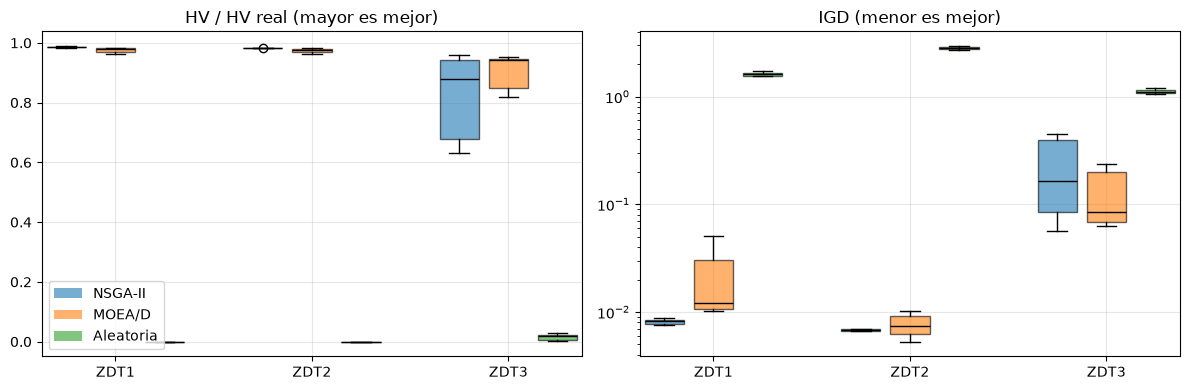

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
algs = ["NSGA-II", "MOEA/D", "Aleatoria"]
for ax, met, titulo in zip(axs, ("HVr", "IGD"), ("HV / HV real (mayor es mejor)", "IGD (menor es mejor)")):
    for k, alg in enumerate(algs):
        for j, t in enumerate(("ZDT1", "ZDT2", "ZDT3")):
            v = [r[met] for r in res[(t, alg)]]
            ax.boxplot(v, positions=[j * 4 + k], widths=0.8, patch_artist=True,
                       boxprops=dict(facecolor=f"C{k}", alpha=.6), medianprops=dict(color="k"))
    ax.set_xticks([1, 5, 9]); ax.set_xticklabels(["ZDT1", "ZDT2", "ZDT3"]); ax.set_title(titulo)
    if met == "IGD": ax.set_yscale("log")
axs[0].legend([plt.Rectangle((0, 0), 1, 1, fc=f"C{k}", alpha=.6) for k in range(3)], algs, loc="lower left")
plt.tight_layout(); plt.show()

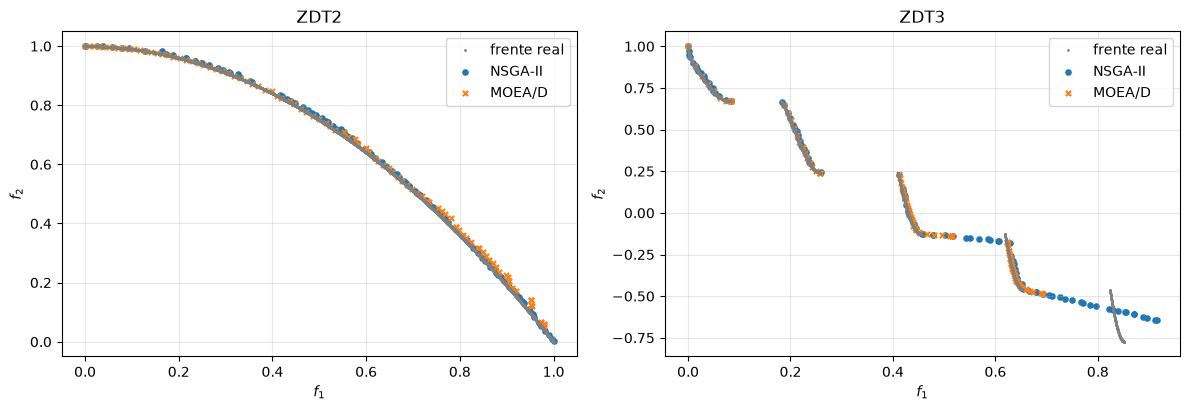

In [15]:
# Gráfico del frente de cada algoritmo en ZDT2 (cóncavo) y ZDT3 (desconectado), semilla fija
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, t in zip(axs, ("ZDT2", "ZDT3")):
    P = reales[t]; ev = zdt(t)
    _, F, f1, _ = correr_nsga2_zdt(t, 7)
    _, Fm, f1m, _ = moead(ev, init_real, mut_real, cruce_real, 100, 400, np.random.default_rng(7))
    ax.plot(*P.T, ".", ms=2, c="gray", label="frente real")
    ax.scatter(*F[f1].T, s=14, c="C0", label="NSGA-II")
    ax.scatter(*Fm[f1m].T, s=14, marker="x", c="C1", label="MOEA/D")
    ax.set_title(t); ax.set_xlabel("$f_1$"); ax.set_ylabel("$f_2$"); ax.legend()
plt.tight_layout(); plt.show()

In [16]:
# Verificación cualitativa automática (se imprime; el markdown de abajo solo la interpreta)
from scipy.stats import wilcoxon
for t in ("ZDT1", "ZDT2", "ZDT3"):
    m = {alg: np.mean([r["HVr"] for r in res[(t, alg)]]) for alg in algs}
    mejor = max(m, key=m.get)
    print(t, {k: round(v, 4) for k, v in m.items()}, "-> mejor HV medio:", mejor)
    a = [r["HVr"] for r in res[(t, "NSGA-II")]]; b = [r["HVr"] for r in res[(t, "MOEA/D")]]
    print(f"    Wilcoxon pareado NSGA-II vs MOEA/D (HV, {len(a)} semillas): p = {wilcoxon(a, b).pvalue:.3f}")

ZDT1 {'NSGA-II': np.float64(0.9859), 'MOEA/D': np.float64(0.976), 'Aleatoria': np.float64(0.0)} -> mejor HV medio: NSGA-II
    Wilcoxon pareado NSGA-II vs MOEA/D (HV, 6 semillas): p = 0.062
ZDT2 {'NSGA-II': np.float64(0.9826), 'MOEA/D': np.float64(0.9744), 'Aleatoria': np.float64(0.0)} -> mejor HV medio: NSGA-II
    Wilcoxon pareado NSGA-II vs MOEA/D (HV, 6 semillas): p = 0.031
ZDT3 {'NSGA-II': np.float64(0.8209), 'MOEA/D': np.float64(0.903), 'Aleatoria': np.float64(0.0148)} -> mejor HV medio: MOEA/D
    Wilcoxon pareado NSGA-II vs MOEA/D (HV, 6 semillas): p = 0.312


**Interpretación (verifica contra la tabla, los gráficos de cajas y los tests impresos).**
- La búsqueda aleatoria queda muy por detrás: en 30 dimensiones casi nunca se obtiene $g\approx1$; la presión evolutiva marca la diferencia.
- En ZDT1 y ZDT2, NSGA-II alcanza un HV relativo muy cercano a 1 y con dispersión mínima entre semillas; MOEA/D queda ligeramente por debajo y es más variable. Ambos aproximan bien el frente cóncavo de ZDT2, donde una suma ponderada fallaría.
- ZDT3 (frente desconectado, con muchos frentes locales) es más difícil: la dispersión entre semillas es mucho mayor y, en esta configuración, MOEA/D obtiene en promedio mejor HV que NSGA-II. Con solo 6 semillas y esa varianza, el test de Wilcoxon impreso debe leerse con cautela (ver [14 · Medición de desempeño](../05-evaluacion-y-ajuste/14-medicion-de-desempeno.ipynb)).
- Cuidado con el *spread*: se mide contra los extremos del frente real y en ZDT3 los saltos entre tramos cuentan como "no uniformidad", de modo que pierde sentido. **Ninguna métrica sola cuenta la historia completa.**

## 7. Problema combinatorio: mochila biobjetivo

**Mochila 0/1 con 2 objetivos:** $n$ ítems con peso $w_j$ y dos beneficios $p^{(1)}_j,p^{(2)}_j$ (p. ej. beneficio económico y beneficio social). Se elige un subconjunto $x\in\{0,1\}^n$ con $\sum w_jx_j\le C$ que **maximiza** ambos beneficios. Para usar nuestras utilidades (minimización) minimizamos $(-P_1,-P_2)$.

**Representación y operadores:** vector binario; cruce uniforme; mutación *bit-flip* con prob. $1/n$; **reparación** golosa: mientras se exceda $C$, quitar el ítem presente con menor razón $(p^{(1)}_j/\bar p^{(1)}+p^{(2)}_j/\bar p^{(2)})/w_j$.

**Validación con el frente exacto:** con $n=20$ podemos enumerar los $2^{20}\approx10^6$ subconjuntos y obtener el frente de Pareto **real**; así sí podemos calcular HV/IGD respecto a la verdad.

In [17]:
def instancia_mochila(n, seed):
    r = np.random.default_rng(seed)
    w = r.integers(5, 40, n).astype(float)
    p1 = r.integers(5, 50, n).astype(float)
    p2 = np.clip(60 - p1 + r.integers(-15, 16, n), 3, None).astype(float)   # beneficios parcialmente en conflicto
    return dict(w=w, p1=p1, p2=p2, C=0.5 * w.sum())

def evaluar_mochila(X, inst):
    '''F = (-P1, -P2) para cada fila de X (binaria).'''
    return -np.column_stack([X @ inst["p1"], X @ inst["p2"]])

def reparar(X, inst):
    '''Quita ítems de menor razón de beneficio/peso hasta cumplir la capacidad (in place).'''
    razon = (inst["p1"] / inst["p1"].mean() + inst["p2"] / inst["p2"].mean()) / inst["w"]
    orden = np.argsort(razon)                      # de menor a mayor razón
    for x in X:
        exceso = x @ inst["w"] - inst["C"]
        if exceso > 0:
            for j in orden:
                if x[j]:
                    x[j] = 0; exceso -= inst["w"][j]
                    if exceso <= 0: break
    return X

def frente_exacto_mochila(inst):
    n = len(inst["w"]); M = 1 << n
    ids = np.arange(M, dtype=np.int64)
    W = np.zeros(M); P1 = np.zeros(M); P2 = np.zeros(M)
    for j in range(n):
        b = ((ids >> j) & 1).astype(float)
        W += b * inst["w"][j]; P1 += b * inst["p1"][j]; P2 += b * inst["p2"][j]
    ok = W <= inst["C"]
    return nd2d(-np.column_stack([P1[ok], P2[ok]]))

inst20 = instancia_mochila(20, 42)
t0 = time.time(); P_exacto = frente_exacto_mochila(inst20)
print(f"frente exacto n=20: {len(P_exacto)} puntos no dominados ({time.time()-t0:.1f}s de enumeración)")

# validación de la reparación y de la evaluación
r = np.random.default_rng(0)
Xt = reparar((r.random((500, 20)) < 0.8).astype(float), inst20)
assert (Xt @ inst20["w"] <= inst20["C"] + 1e-9).all()
print("reparación: las 500 soluciones de prueba cumplen la capacidad")

frente exacto n=20: 28 puntos no dominados (0.1s de enumeración)
reparación: las 500 soluciones de prueba cumplen la capacidad


semilla 0: 22 de 28 puntos del frente exacto hallados


semilla 1: 24 de 28 puntos del frente exacto hallados


semilla 2: 21 de 28 puntos del frente exacto hallados


HV/HV_exacto en 10 semillas: media=0.9571, min=0.9359, max=0.9888
IGD en 10 semillas: media=20.683


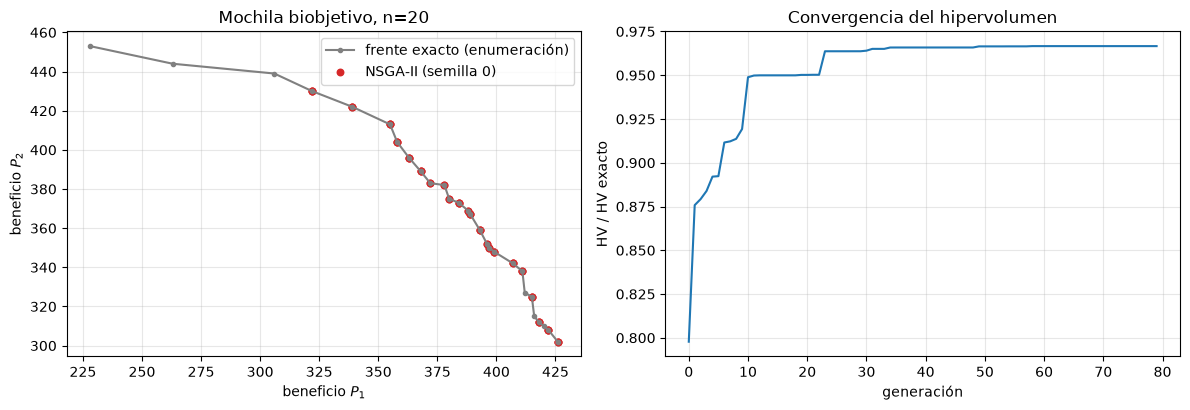

In [18]:
def hacer_mochila(inst):
    n = len(inst["w"])
    def init(N, rng):
        return reparar((rng.random((N, n)) < 0.5).astype(float), inst)
    def var(Xp, rng):
        N = len(Xp)
        perm = rng.permutation(N)
        A, B = Xp, Xp[perm]
        mask = rng.random(A.shape) < 0.5                       # cruce uniforme
        H = np.where(mask, A, B)
        H = np.where(rng.random(H.shape) < 1.0 / n, 1 - H, H)  # bit-flip
        return reparar(H, inst)
    return (lambda X: evaluar_mochila(X, inst)), init, var

ev20, init20, var20 = hacer_mochila(inst20)
ref20 = np.array([0.0, 0.0])                                    # en -P: el origen es el "peor" (0 beneficio)
hv_ex = hipervolumen_2d(P_exacto, ref20)
hvs, igds, hist_ejemplo = [], [], None
for s in range(10):
    rng = np.random.default_rng(1000 + s)
    X, F, f1, hist = nsga2(ev20, init20, var20, 60, 80, rng, hist_fn=lambda Ff: hipervolumen_2d(Ff, ref20))
    hvs.append(hipervolumen_2d(F[f1], ref20) / hv_ex); igds.append(IGD(F[f1], P_exacto))
    # contención: cuántos puntos del frente exacto fueron hallados exactamente
    if s == 0: hist_ejemplo, F0, f10 = hist, F, f1
    encontrados = {tuple(p) for p in np.round(P_exacto, 6)} & {tuple(p) for p in np.round(F[f1], 6)}
    if s < 3: print(f"semilla {s}: {len(encontrados)} de {len(P_exacto)} puntos del frente exacto hallados")
print(f"HV/HV_exacto en 10 semillas: media={np.mean(hvs):.4f}, min={np.min(hvs):.4f}, max={np.max(hvs):.4f}")
print(f"IGD en 10 semillas: media={np.mean(igds):.3f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
axs[0].plot(*(-P_exacto).T, "o-", c="gray", ms=3, label="frente exacto (enumeración)")
axs[0].scatter(*(-F0[f10]).T, s=22, c="C3", label="NSGA-II (semilla 0)")
axs[0].set_xlabel("beneficio $P_1$"); axs[0].set_ylabel("beneficio $P_2$"); axs[0].set_title("Mochila biobjetivo, n=20"); axs[0].legend()
axs[1].plot(np.array(hist_ejemplo) / hv_ex); axs[1].set_xlabel("generación"); axs[1].set_ylabel("HV / HV exacto")
axs[1].set_title("Convergencia del hipervolumen"); plt.tight_layout(); plt.show()

### Instancia grande (n = 100): sin frente exacto
Para $n=100$ no hay enumeración posible. Comparamos cuatro métodos con hipervolumen y punto de referencia común (no hay frente verdadero: solo comparamos algoritmos entre sí): NSGA-II estándar; NSGA-II **sembrado** (la mitad de la población inicial son soluciones golosas con pesos aleatorios: un pequeño híbrido, tema del [notebook 13](13-metodos-hibridos-y-paralelos.ipynb)); una **heurística golosa ponderada** (21 pesos, un punto por peso, solo 21 evaluaciones); y búsqueda aleatoria con reparación. La greedy por razón beneficio/peso es una heurística muy fuerte en mochila, y es una línea base honesta que un MOEA genérico no siempre supera.

tiempo 8s
HV NSGA-II               :      4705908 +-    30559
HV NSGA-II sembrado      :      5108979 +-     4054
HV Goloso ponderado      :      5081906 +-        0
HV Aleatoria+reparación  :      3626726 +-    60211


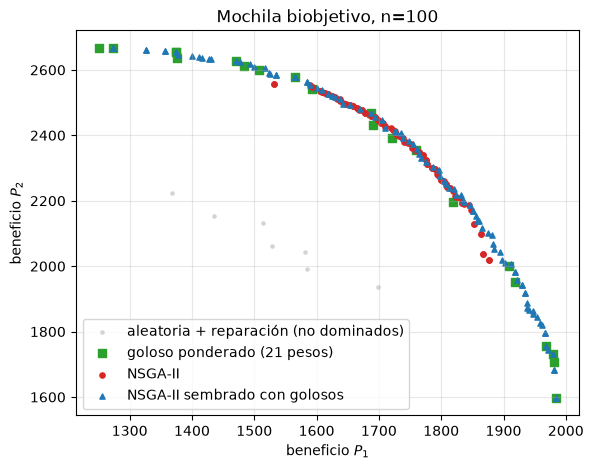

In [19]:
inst100 = instancia_mochila(100, 7)
ev100, init100, var100 = hacer_mochila(inst100)
ref100 = np.array([0.0, 0.0])

def greedy_ponderado(inst, w):
    '''Solución golosa para el beneficio w*P1+(1-w)*P2: se agregan ítems por razón decreciente.'''
    val = w * inst["p1"] + (1 - w) * inst["p2"]
    x = np.zeros(len(val)); carga = 0.0
    for j in np.argsort(-val / inst["w"]):
        if carga + inst["w"][j] <= inst["C"]:
            x[j] = 1; carga += inst["w"][j]
    return x

def init_sembrada(N, rng):
    '''Mitad de la población: soluciones golosas con pesos aleatorios (híbrido); mitad aleatoria.'''
    X = init100(N, rng)
    k = N // 2
    X[:k] = np.array([greedy_ponderado(inst100, w) for w in rng.random(k)])
    return X

# Todos con ~20 000 evaluaciones. NSGA-II: N=100, G=200
hv = {"NSGA-II": [], "NSGA-II sembrado": [], "Goloso ponderado": [], "Aleatoria+reparación": []}
t0 = time.time()
for s in range(6):
    rng = np.random.default_rng(2000 + s)
    X, F, f1, _ = nsga2(ev100, init100, var100, 100, 200, rng)
    hv["NSGA-II"].append(hipervolumen_2d(F[f1], ref100))
    X, F, f1, _ = nsga2(ev100, init_sembrada, var100, 100, 200, rng)
    hv["NSGA-II sembrado"].append(hipervolumen_2d(F[f1], ref100))
    Fg = ev100(np.array([greedy_ponderado(inst100, w) for w in np.linspace(0, 1, 21)]))
    hv["Goloso ponderado"].append(hipervolumen_2d(Fg, ref100))
    hv["Aleatoria+reparación"].append(hipervolumen_2d(ev100(init100(20000, rng)), ref100))
print(f"tiempo {time.time()-t0:.0f}s")
for k, v in hv.items():
    print(f"HV {k:22s}: {np.mean(v):12.0f} +- {np.std(v):8.0f}")

rng = np.random.default_rng(2000)
X, F, f1, _ = nsga2(ev100, init100, var100, 100, 200, rng)
X2, F2, f2_, _ = nsga2(ev100, init_sembrada, var100, 100, 200, np.random.default_rng(2000))
Fg = ev100(np.array([greedy_ponderado(inst100, w) for w in np.linspace(0, 1, 21)]))
Fa = nd2d(ev100(init100(20000, np.random.default_rng(1))))
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(*(-Fa).T, s=5, c="lightgray", label="aleatoria + reparación (no dominados)")
ax.scatter(*(-Fg).T, s=40, marker="s", c="C2", label="goloso ponderado (21 pesos)")
ax.scatter(*(-F[f1]).T, s=14, c="C3", label="NSGA-II")
ax.scatter(*(-F2[f2_]).T, s=14, marker="^", c="C0", label="NSGA-II sembrado con golosos")
ax.set_xlabel("beneficio $P_1$"); ax.set_ylabel("beneficio $P_2$"); ax.set_title("Mochila biobjetivo, n=100"); ax.legend(); plt.show()

## 8. Ventajas y limitaciones

| Enfoque | Ventajas | Limitaciones |
|---|---|---|
| Suma ponderada | simple; reutiliza cualquier solver mono-objetivo | no alcanza puntos no convexos; un solver por punto; distribución de puntos incontrolable |
| $\varepsilon$-constraint | alcanza todo el frente; el decisor interpreta $\varepsilon$ | elegir rangos de $\varepsilon$; subproblemas infactibles; un solver por punto |
| NSGA-II | un frente completo en una corrida; sin supuestos de forma; robusto y popular | pierde presión de selección con $m\ge 4$ objetivos (casi todos no dominados); crowding poco informativo en alta dimensión |
| SPEA2 | densidad basada en $k$-vecinos; archivo externo | coste del truncado y del cálculo de distancias |
| MOEA/D | muy eficiente; distribución regular; escala mejor a muchos objetivos | requiere elegir pesos, vecindario y la escalarización; sensible a la forma del frente (pesos uniformes) |

**Buenas prácticas:** (i) usar **varias semillas** y reportar media y dispersión de HV/IGD; (ii) fijar el mismo presupuesto de evaluaciones; (iii) normalizar los objetivos antes de calcular indicadores si sus escalas difieren; (iv) preferir HV como indicador unario compatible con Pareto, y complementarlo con IGD cuando se conozca el frente real.

## Resumen
- La dominancia de Pareto es un orden parcial; el resultado de un problema multiobjetivo es un conjunto de compromisos.
- La suma ponderada solo alcanza el casco convexo del frente (lo comprobamos con ZDT cóncavo); $\varepsilon$-constraint y Tchebycheff no tienen esa limitación.
- NSGA-II = ordenamiento por no-dominancia + crowding + torneo apiñado + elitismo $(\mu+\lambda)$; lo validamos contra fuerza bruta.
- Los indicadores (HV, GD, IGD, spread) miden aspectos distintos; validamos el HV contra Monte Carlo y contra el frente exacto de una mochila de 20 ítems.
- Los resultados se comparan en **varias semillas** y con una línea base aleatoria.

## Ejercicios propuestos
1. Implementa el **crowding distance con normalización por rango global** (en lugar del rango del frente) y compara el spread en ZDT3.
2. Implementa el cálculo de fuerza/*fitness* de **SPEA2** y reemplaza la selección de NSGA-II. ¿Cambia el HV en ZDT1–3?
3. Cambia MOEA/D a **suma ponderada** en lugar de Tchebycheff y repite ZDT2. ¿Qué observas en el frente?
4. Extiende el hipervolumen a 3 objetivos (p. ej. por rebanadas) y prueba con DTLZ2.
5. **TSP biobjetivo:** crea dos matrices de costo (distancia y "riesgo") y adapta NSGA-II con cruce OX y mutación por intercambio.
6. Estudia el efecto de $N$ y $G$ a presupuesto fijo ($N\cdot G=40\,000$) sobre HV en ZDT1.

## Referencias
- Deb, K., Pratap, A., Agarwal, S., Meyarivan, T. (2002). *A fast and elitist multiobjective genetic algorithm: NSGA-II.* IEEE Transactions on Evolutionary Computation.
- Zitzler, E., Laumanns, M., Thiele, L. (2001). *SPEA2: Improving the strength Pareto evolutionary algorithm.* TIK-Report 103, ETH Zürich.
- Zhang, Q., Li, H. (2007). *MOEA/D: A multiobjective evolutionary algorithm based on decomposition.* IEEE Transactions on Evolutionary Computation.
- Zitzler, E., Deb, K., Thiele, L. (2000). *Comparison of multiobjective evolutionary algorithms: Empirical results.* Evolutionary Computation.
- Deb, K. (2001). *Multi-Objective Optimization using Evolutionary Algorithms.* Wiley.
- Zitzler, E., Thiele, L., Laumanns, M., Fonseca, C., da Fonseca, V. (2003). *Performance assessment of multiobjective optimizers: an analysis and review.* IEEE Transactions on Evolutionary Computation.
- Miettinen, K. (1999). *Nonlinear Multiobjective Optimization.* Kluwer.

In [20]:
print(f"Tiempo total de la notebook: {time.time()-t_inicio_notebook:.0f}s")

Tiempo total de la notebook: 105s
